# Module 3 - Data Visualization
**What this module covers:** **accident maps** (interactive Folium MarkerCluster coloured by severity + a static PNG),
**heatmaps** (full-data hotspot density, Folium HeatMap weighted by severity, hour x weekday matrix, correlation
heatmap), **time-series plots** (monthly trend with rolling means, hourly profile, severity share over time; PNG +
interactive Plotly HTML), weather vs severity charts and a one-page **dashboard overview**.

**Project tasks satisfied here:** *accident maps, heatmaps, time-series plots, dashboard* (the dashboard page here
plus the interactive Streamlit app in `app/`).

Input: `data/processed/accidents_clean.parquet` (cleaned sample) and the full-data hotspot grid from Module 1.
Outputs: `reports/maps/*.html`, `reports/figures/*`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster, HeatMap
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from src import utils as U, viz as V
from src.analysis import group_summary

V.apply_style()
df = pd.read_parquet(U.CLEAN_PARQUET)
FIG, MAPS = U.FIGURES, U.MAPS
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| folium", folium.__version__, "| interpreter:", Path(sys.executable).parent.parent.name)
print(f"Rows: {len(df):,}")

Python 3.14.2 | pandas 3.1.0 | folium 0.20.0 | interpreter: .venv
Rows: 399,581


## 1. Accident map - MarkerCluster, 5,000 sampled points coloured by severity

In [2]:
pts = df.sample(5000, random_state=U.RANDOM_STATE)
m = folium.Map(location=[39.5, -98.35], zoom_start=4, tiles="cartodbpositron")
mc = MarkerCluster(name="Accidents").add_to(m)
for r in pts.itertuples():
    folium.CircleMarker(location=[r.Start_Lat, r.Start_Lng], radius=5, color=V.SEVERITY[r.Severity], fill=True,
                        fill_color=V.SEVERITY[r.Severity], fill_opacity=0.9, weight=1,
                        popup=f"Severity {r.Severity}<br>{r.City}, {r.State}<br>{r.Start_Time:%Y-%m-%d %H:%M}<br>{r.WeatherGroup}").add_to(mc)
legend = ('<div style="position:fixed;bottom:24px;left:24px;z-index:9999;background:#fcfcfb;padding:8px 12px;'
          'border:1px solid #c3c2b7;border-radius:6px;font:12px sans-serif;color:#0b0b0b"><b>Severity</b><br>' +
          "".join(f'<span style="display:inline-block;width:10px;height:10px;border-radius:5px;background:{c};margin-right:6px"></span>{s}<br>'
                  for s, c in V.SEVERITY.items()) + "</div>")
m.get_root().html.add_child(folium.Element(legend))
m.save(MAPS / "accident_map.html")
print("Saved reports/maps/accident_map.html with", len(pts), "points;", pts["Severity"].value_counts().sort_index().to_dict())

C:\Users\abins\Documents\Smart-Traffic-Accident-Analysis-and-Severity-Prediction\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Saved reports/maps/accident_map.html with 5000 points; {1: 40, 2: 3961, 3: 870, 4: 129}


### 1.1 Static accident map (PNG, 50,000 sampled points; Severity 3-4 drawn on top)

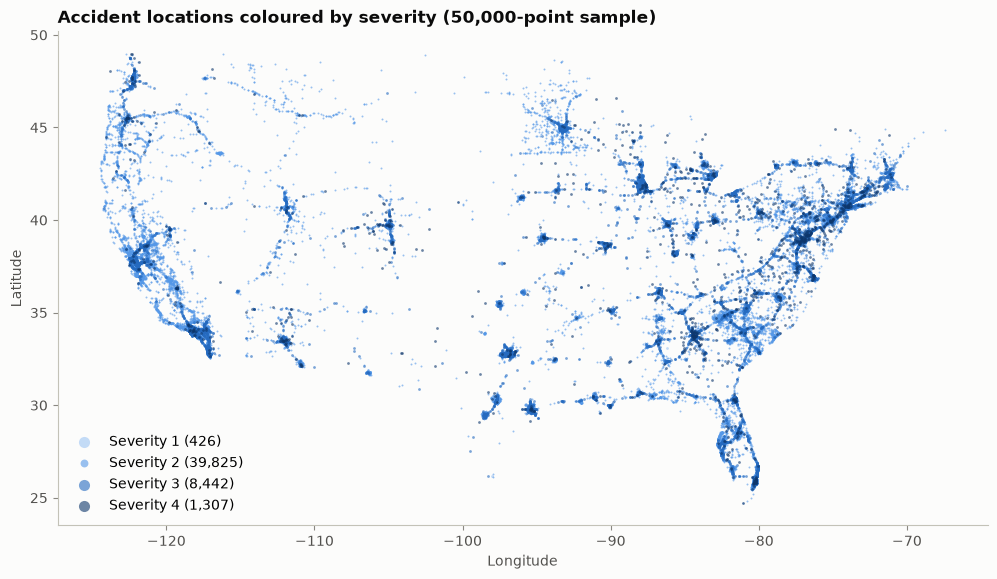

In [3]:
mp = df.sample(50_000, random_state=U.RANDOM_STATE).sort_values("Severity")
fig, ax = plt.subplots(figsize=(12, 6.6))
for s in [1, 2, 3, 4]:
    m = mp["Severity"] == s
    ax.scatter(mp.loc[m, "Start_Lng"], mp.loc[m, "Start_Lat"], s=2 if s == 2 else 4, color=V.SEVERITY[s], alpha=0.6,
               linewidths=0, label=f"Severity {s} ({m.sum():,})")
ax.set(title="Accident locations coloured by severity (50,000-point sample)", xlabel="Longitude", ylabel="Latitude")
ax.legend(markerscale=4, loc="lower left"); ax.grid(False); ax.set_aspect(1.25)
V.save(fig, FIG / "accident_map.png")

## 2. Heatmaps
### 2.0 Hotspot density heatmap - all 7.7M records on the 0.1-degree grid (log colour scale)

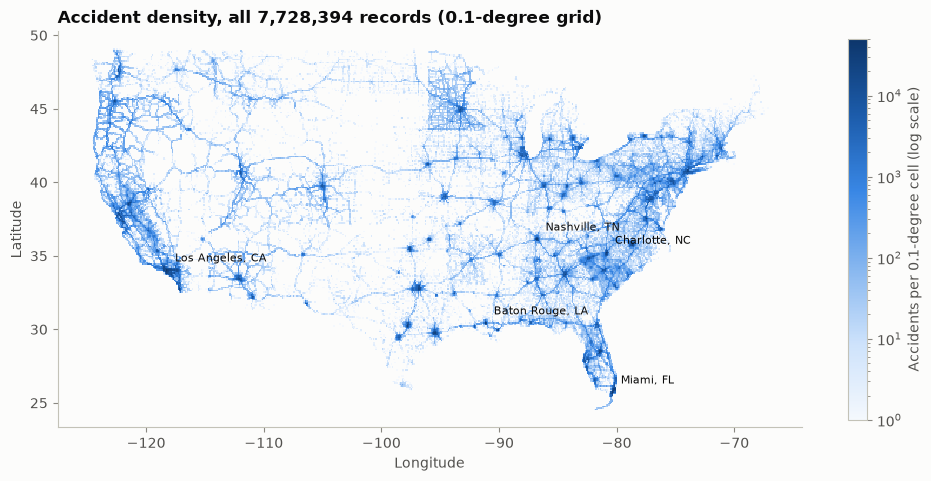

In [4]:
from matplotlib.colors import LogNorm
grid = pd.read_parquet(U.DATA_PROCESSED / "full_hotspot_grid.parquet")
cells = grid.groupby(["cell_lat", "cell_lng"])["n"].sum().reset_index()
fig, ax = plt.subplots(figsize=(12, 6.6))
sc = ax.scatter(cells["cell_lng"] + 0.05, cells["cell_lat"] + 0.05, c=cells["n"], s=1.6, marker="s", cmap=V.SEQ_CMAP,
                norm=LogNorm(vmin=1, vmax=cells["n"].max()), linewidths=0)
fig.colorbar(sc, ax=ax, shrink=0.75, label="Accidents per 0.1-degree cell (log scale)")
hot = pd.read_csv(U.METRICS / "hotspots.csv")
for r in hot.drop_duplicates("label").head(5).itertuples():
    ax.annotate(r.label, (r.center_lng, r.center_lat), xytext=(6, 6), textcoords="offset points", fontsize=8, color=V.INK)
ax.set(title=f"Accident density, all {cells['n'].sum():,} records (0.1-degree grid)", xlabel="Longitude", ylabel="Latitude")
ax.grid(False); ax.set_aspect(1.25)
V.save(fig, FIG / "hotspot_density_heatmap.png")

### 2.1 Folium HeatMap weighted by severity (50,000 sampled points)

In [5]:
hp = df.sample(50_000, random_state=U.RANDOM_STATE)
hm = folium.Map(location=[39.5, -98.35], zoom_start=4, tiles="cartodbpositron")
HeatMap(hp[["Start_Lat", "Start_Lng", "Severity"]].assign(w=lambda d: d["Severity"] / 4)[["Start_Lat", "Start_Lng", "w"]].values.tolist(),
        radius=8, blur=10, min_opacity=0.3, max_zoom=8).add_to(hm)
hm.save(MAPS / "accident_heatmap.html")
print("Saved reports/maps/accident_heatmap.html with", len(hp), "points (weight = Severity / 4)")

C:\Users\abins\Documents\Smart-Traffic-Accident-Analysis-and-Severity-Prediction\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Saved reports/maps/accident_heatmap.html with 50000 points (weight = Severity / 4)


### 2.2 Hour x weekday heatmap

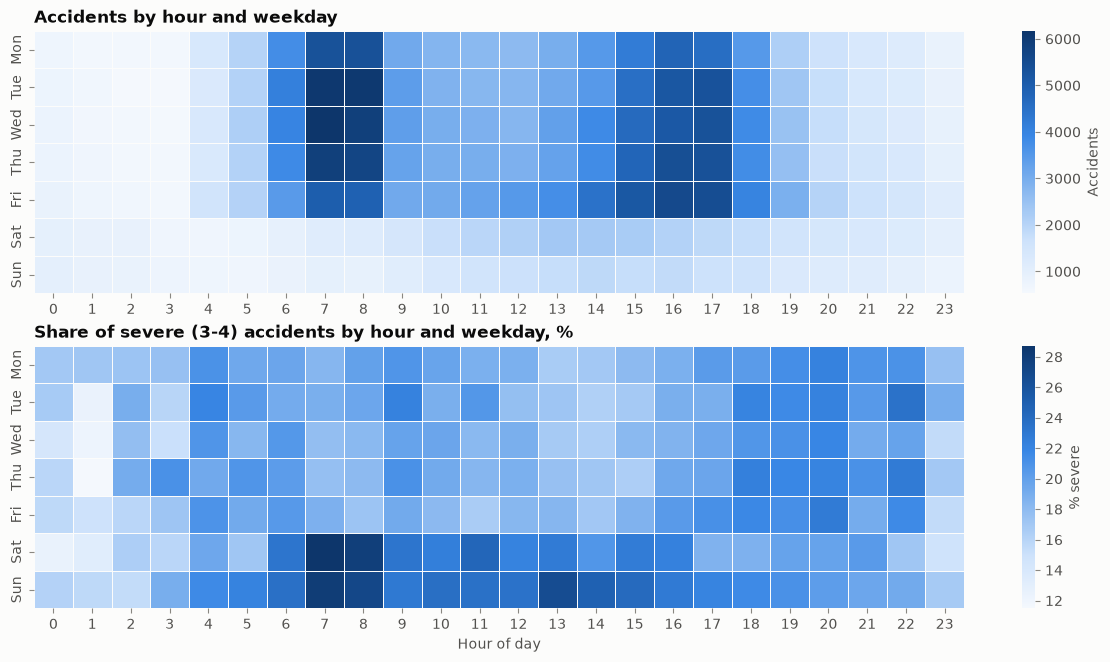

Busiest slot: Wed 07:00 with 6,169 accidents in the sample


In [6]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
hw = pd.crosstab(df["DayOfWeek"], df["Hour"]); hw.index = days
hw_sev = df.assign(s=(df["Severity"] >= 3)).pivot_table(index="DayOfWeek", columns="Hour", values="s", aggfunc="mean") * 100; hw_sev.index = days
hw.to_csv(U.METRICS / "hour_weekday_counts.csv")
fig, axes = plt.subplots(2, 1, figsize=(15, 7.5))
sns.heatmap(hw, ax=axes[0], cmap=V.SEQ_CMAP, cbar_kws={"label": "Accidents"}, linewidths=0.5, linecolor=V.SURFACE)
axes[0].set(title="Accidents by hour and weekday", xlabel="", ylabel="")
sns.heatmap(hw_sev, ax=axes[1], cmap=V.SEQ_CMAP, cbar_kws={"label": "% severe"}, linewidths=0.5, linecolor=V.SURFACE)
axes[1].set(title="Share of severe (3-4) accidents by hour and weekday, %", xlabel="Hour of day", ylabel="")
for a in axes: a.grid(False)
V.save(fig, FIG / "heatmap_hour_weekday.png")
mx = hw.stack().idxmax()
print(f"Busiest slot: {mx[0]} {mx[1]:02d}:00 with {hw.loc[mx]:,} accidents in the sample")

## 3. Time series
Counts are from the 5.18% stratified sample, so they show the **shape** of the trend; full-data yearly totals are in
`reports/metrics/full_year_counts.csv`. 2016 starts in February and 2023 ends in March (partial years).

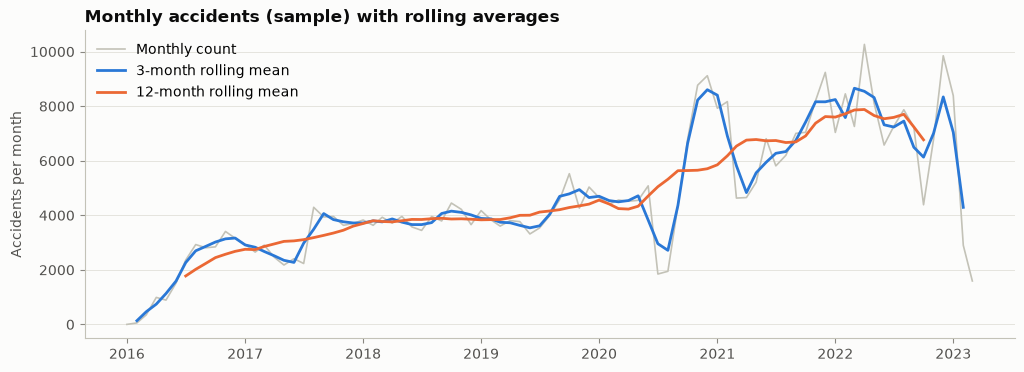

Peak month in the sample: April 2022 (10,265)


In [7]:
monthly = df.groupby(df["Start_Time"].dt.to_period("M")).agg(accidents=("Severity", "size"),
                                                             severe_pct=("Severity", lambda s: 100 * (s >= 3).mean()))
monthly.index = monthly.index.to_timestamp()
monthly["rolling_3m"] = monthly["accidents"].rolling(3, center=True).mean()
monthly["rolling_12m"] = monthly["accidents"].rolling(12, center=True).mean()
monthly.round(2).to_csv(U.METRICS / "monthly_trend.csv", index_label="month")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly["accidents"], color=V.AXIS, lw=1.2, label="Monthly count")
ax.plot(monthly.index, monthly["rolling_3m"], color=V.PRIMARY, lw=2, label="3-month rolling mean")
ax.plot(monthly.index, monthly["rolling_12m"], color=V.ACCENT, lw=2, label="12-month rolling mean")
ax.set(title="Monthly accidents (sample) with rolling averages", ylabel="Accidents per month"); ax.legend(loc="upper left")
V.save(fig, FIG / "timeseries_monthly.png")
pk = monthly["accidents"].idxmax()
print(f"Peak month in the sample: {pk:%B %Y} ({int(monthly.loc[pk, 'accidents']):,})")

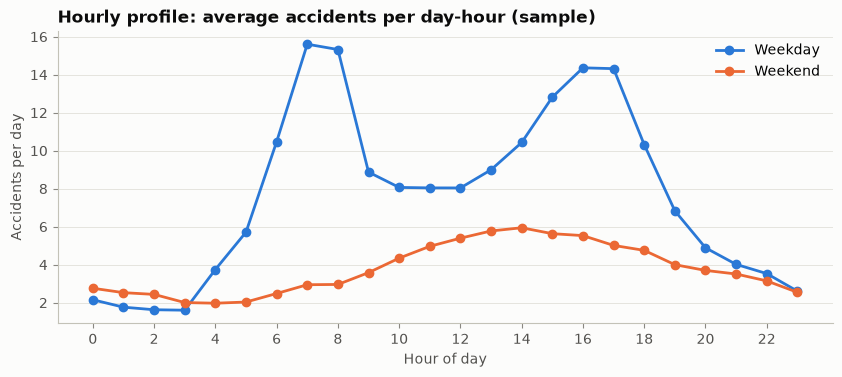

In [8]:
hourly = df.groupby(["Hour", "IsWeekend"]).size().unstack()
hourly = hourly / [df.loc[df.IsWeekend == 0, "Start_Time"].dt.date.nunique(), df.loc[df.IsWeekend == 1, "Start_Time"].dt.date.nunique()]
hourly.columns = ["Weekday", "Weekend"]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(hourly.index, hourly["Weekday"], marker="o", color=V.PRIMARY, label="Weekday")
ax.plot(hourly.index, hourly["Weekend"], marker="o", color=V.ACCENT, label="Weekend")
ax.set(title="Hourly profile: average accidents per day-hour (sample)", xlabel="Hour of day", ylabel="Accidents per day")
ax.set_xticks(range(0, 24, 2)); ax.legend()
V.save(fig, FIG / "timeseries_hourly_profile.png")

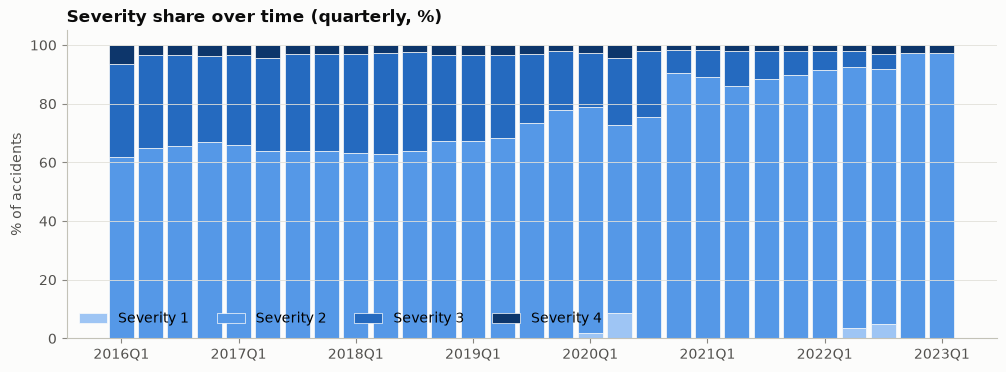

In [9]:
share = pd.crosstab(df["Start_Time"].dt.to_period("Q"), df["Severity"], normalize="index") * 100
share.index = share.index.astype(str)
share.round(2).to_csv(U.METRICS / "severity_share_quarterly.csv")
fig, ax = plt.subplots(figsize=(12, 4))
bottom = np.zeros(len(share))
for s in [1, 2, 3, 4]:
    ax.bar(share.index, share[s], bottom=bottom, color=V.SEVERITY[s], label=f"Severity {s}", width=0.85, edgecolor=V.SURFACE, linewidth=0.5)
    bottom += share[s].values
ax.set(title="Severity share over time (quarterly, %)", ylabel="% of accidents"); ax.legend(ncol=4, loc="lower left")
ax.set_xticks(range(0, len(share), 4)); ax.set_xticklabels(share.index[::4], rotation=0)
V.save(fig, FIG / "timeseries_severity_share.png")

### 3.1 Interactive Plotly version (one HTML file with three linked panels)

In [10]:
figp = make_subplots(rows=3, cols=1, subplot_titles=("Monthly accidents (sample) and 3-month rolling mean",
                                                    "Average accidents per day by hour", "Severity share by quarter (%)"),
                     vertical_spacing=0.09)
figp.add_trace(go.Scatter(x=monthly.index, y=monthly["accidents"], name="Monthly count", line=dict(color=V.AXIS, width=1.5)), 1, 1)
figp.add_trace(go.Scatter(x=monthly.index, y=monthly["rolling_3m"], name="3-month rolling mean", line=dict(color=V.PRIMARY, width=2.5)), 1, 1)
figp.add_trace(go.Scatter(x=hourly.index, y=hourly["Weekday"], name="Weekday", mode="lines+markers", line=dict(color=V.PRIMARY)), 2, 1)
figp.add_trace(go.Scatter(x=hourly.index, y=hourly["Weekend"], name="Weekend", mode="lines+markers", line=dict(color=V.ACCENT)), 2, 1)
for s in [1, 2, 3, 4]:
    figp.add_trace(go.Bar(x=share.index, y=share[s], name=f"Severity {s}", marker_color=V.SEVERITY[s]), 3, 1)
figp.update_layout(barmode="stack", height=1100, template="plotly_white", hovermode="x unified",
                   title="US accidents - time-series explorer", paper_bgcolor=V.SURFACE, plot_bgcolor=V.SURFACE)
figp.write_html(MAPS / "timeseries_interactive.html", include_plotlyjs="cdn")
print("Saved reports/maps/timeseries_interactive.html")

Saved reports/maps/timeseries_interactive.html


## 4. Weather vs severity visuals

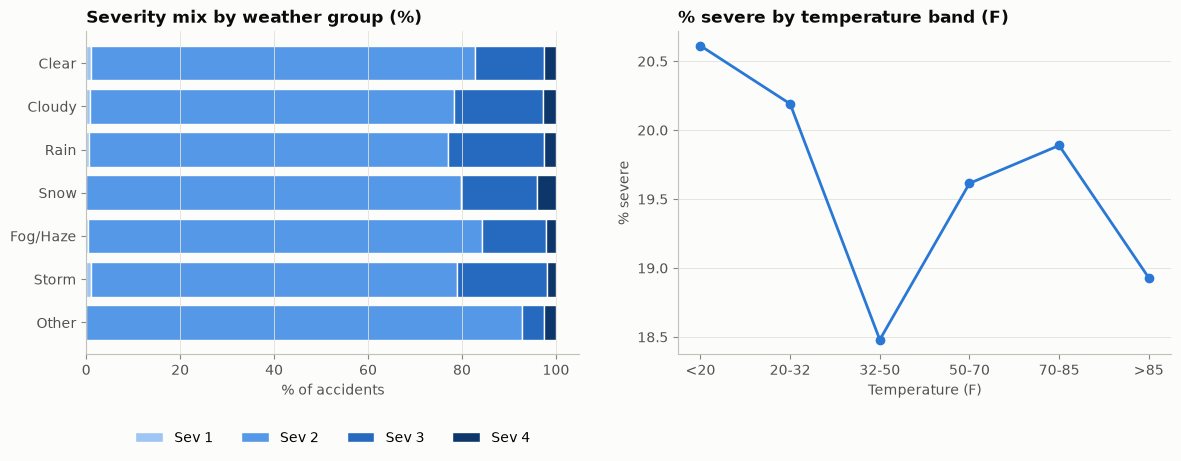

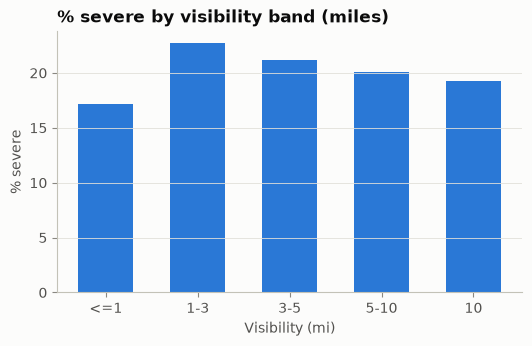

Temperature(F)
<20      20.61
20-32    20.19
32-50    18.48
50-70    19.61
70-85    19.89
>85      18.93
Visibility(mi)
<=1     17.13
1-3     22.71
3-5     21.19
5-10    20.13
10      19.27


In [11]:
order = [g for g in U.WEATHER_GROUPS if g in df["WeatherGroup"].unique()]
ws = pd.crosstab(df["WeatherGroup"], df["Severity"], normalize="index").loc[order] * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
left = np.zeros(len(ws))
for s in [1, 2, 3, 4]:
    axes[0].barh(ws.index, ws[s], left=left, color=V.SEVERITY[s], label=f"Sev {s}", edgecolor=V.SURFACE, linewidth=1)
    left += ws[s].values
axes[0].invert_yaxis(); axes[0].set(title="Severity mix by weather group (%)", xlabel="% of accidents")
axes[0].legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.32)); axes[0].grid(axis="x"); axes[0].grid(axis="y", visible=False)
vis_bins = pd.cut(df["Visibility(mi)"], [-0.01, 1, 3, 5, 9.99, 10], labels=["<=1", "1-3", "3-5", "5-10", "10"])
tmp_bins = pd.cut(df["Temperature(F)"], [-100, 20, 32, 50, 70, 85, 200], labels=["<20", "20-32", "32-50", "50-70", "70-85", ">85"])
vb = df.groupby(vis_bins, observed=True)["Severity"].apply(lambda s: 100 * (s >= 3).mean())
tb = df.groupby(tmp_bins, observed=True)["Severity"].apply(lambda s: 100 * (s >= 3).mean())
axes[1].plot(range(len(tb)), tb.values, marker="o", color=V.PRIMARY, label="by temperature (F)")
axes[1].set_xticks(range(len(tb))); axes[1].set_xticklabels(tb.index)
axes[1].set(title="% severe by temperature band (F)", xlabel="Temperature (F)", ylabel="% severe")
V.save(fig, FIG / "weather_severity_mix.png")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(vb.index.astype(str), vb.values, color=V.PRIMARY, width=0.6)
ax.set(title="% severe by visibility band (miles)", xlabel="Visibility (mi)", ylabel="% severe")
V.save(fig, FIG / "weather_visibility_severity.png")
pd.DataFrame({"temperature_band": tb.index.astype(str), "severe_pct": tb.round(2).values}).to_csv(U.METRICS / "severe_by_temperature_band.csv", index=False)
pd.DataFrame({"visibility_band": vb.index.astype(str), "severe_pct": vb.round(2).values}).to_csv(U.METRICS / "severe_by_visibility_band.csv", index=False)
print(tb.round(2).to_string()); print(vb.round(2).to_string())

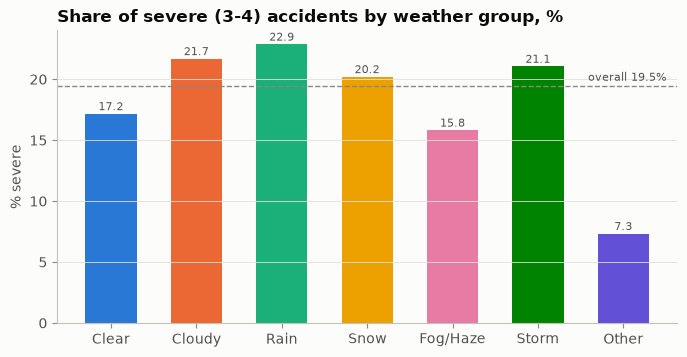

In [12]:
sev_w = group_summary(df, "WeatherGroup").set_index("WeatherGroup").loc[order]
overall = 100 * (df["Severity"] >= 3).mean()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(sev_w.index, sev_w["severe_pct"], color=[V.WEATHER_COLORS[g] for g in sev_w.index], width=0.6)
ax.axhline(overall, color=V.MUTED, ls="--", lw=1); ax.text(len(sev_w) - 0.5, overall + 0.4, f"overall {overall:.1f}%", ha="right", fontsize=8, color=V.INK2)
for i, v in enumerate(sev_w["severe_pct"]):
    ax.text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=8, color=V.INK2)
ax.set(title="Share of severe (3-4) accidents by weather group, %", ylabel="% severe")
V.save(fig, FIG / "weather_severe_share.png")

## 5. Correlation heatmap (matrices computed in Module 2)

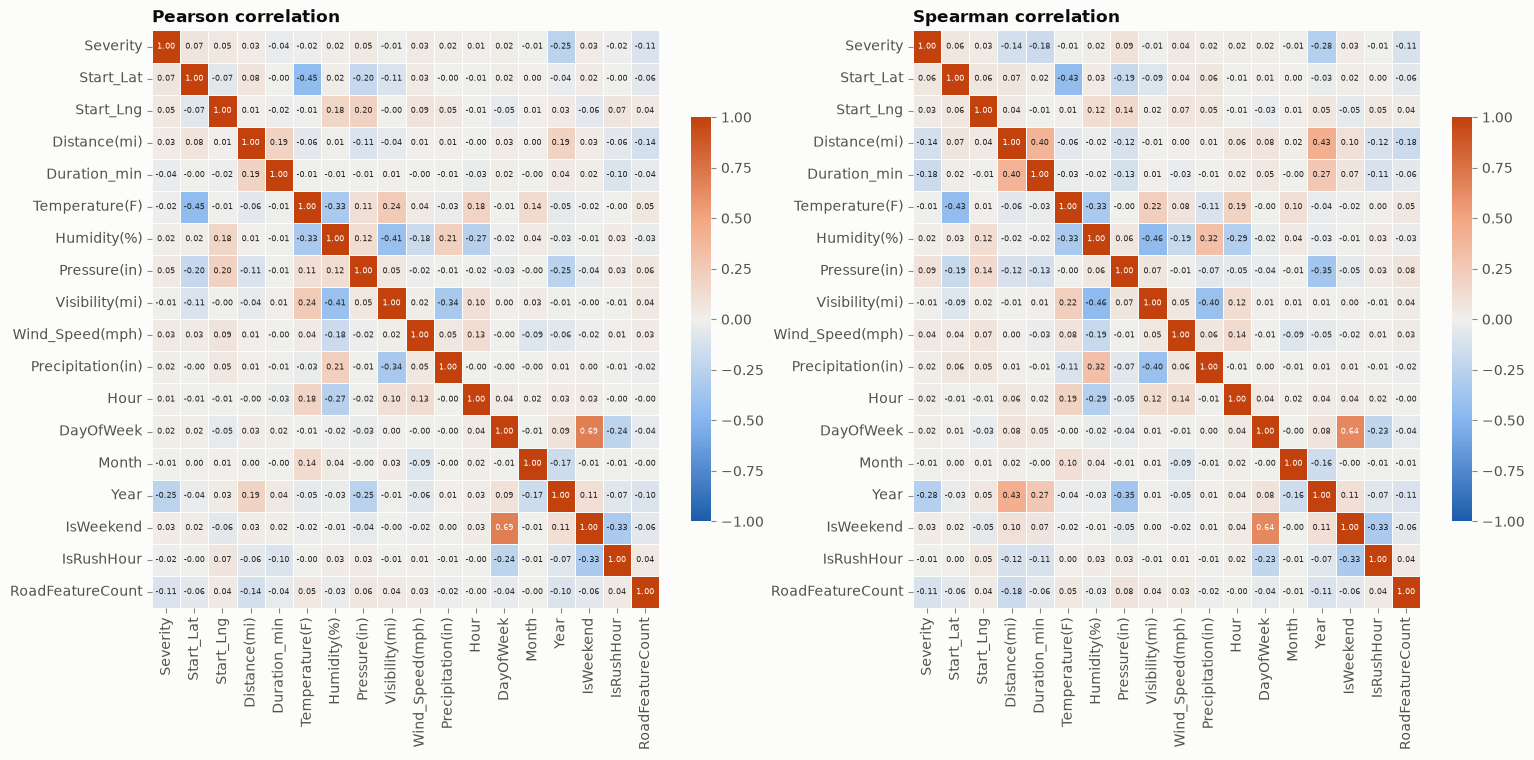

In [13]:
pear = pd.read_csv(U.METRICS / "correlation_pearson.csv", index_col=0)
spear = pd.read_csv(U.METRICS / "correlation_spearman.csv", index_col=0)
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for a, m, t in zip(axes, [pear, spear], ["Pearson", "Spearman"]):
    sns.heatmap(m, ax=a, cmap=V.DIV_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 6},
                cbar_kws={"shrink": 0.7}, linewidths=0.5, linecolor=V.SURFACE)
    a.set_title(f"{t} correlation"); a.grid(False)
V.save(fig, FIG / "correlation_heatmaps.png")

## 6. Dashboard overview (one page)
KPI strip, top-10 states, severity mix, accidents by hour, severe share by weather and the monthly trend.

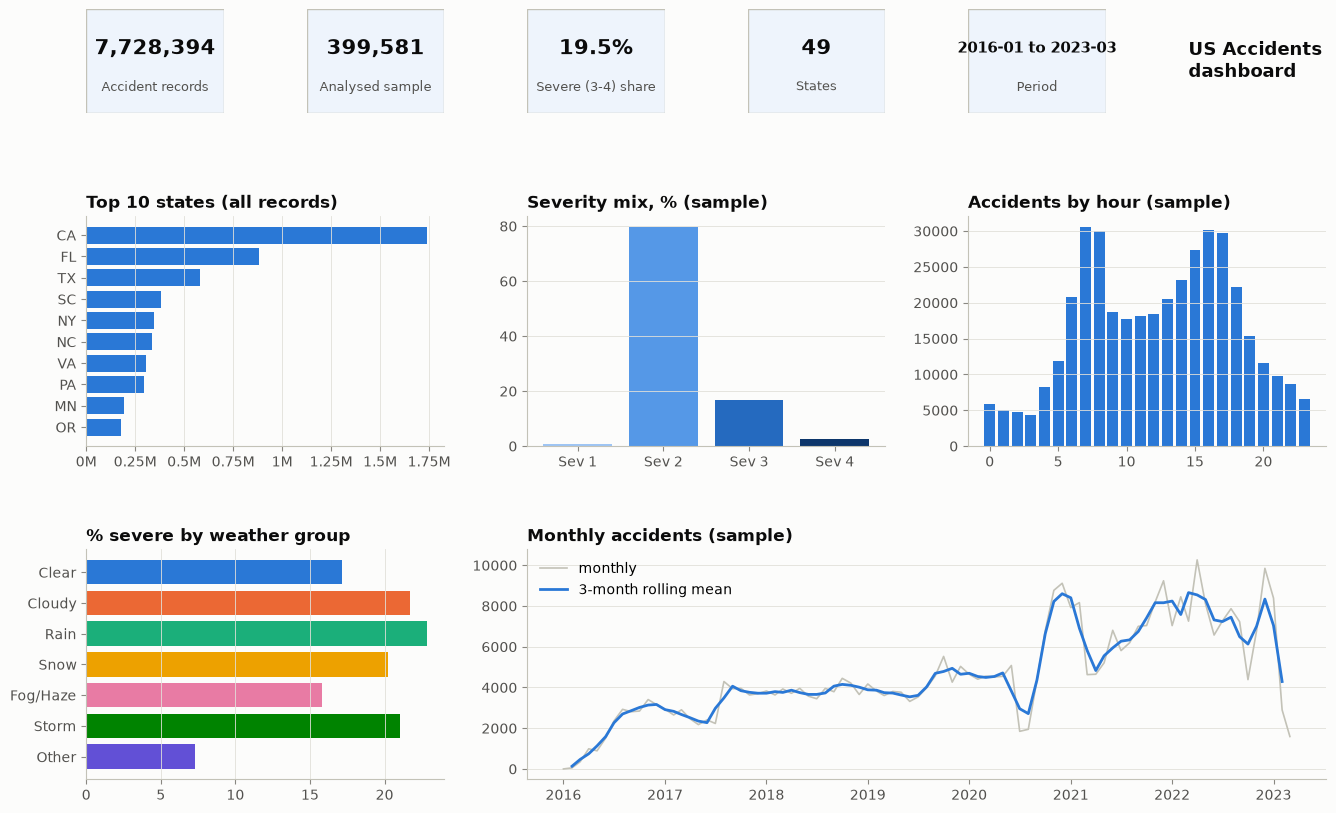

In [14]:
prof = U.load_json(U.METRICS / "dataset_profile.json")
states = pd.read_csv(U.METRICS / "top_states_full.csv").head(10)
sev_mix = df["Severity"].value_counts(normalize=True).sort_index() * 100
by_h = df.groupby("Hour").size()
kpis = [("Accident records", f"{prof['rows']:,}"), ("Analysed sample", f"{len(df):,}"),
        ("Severe (3-4) share", f"{overall:.1f}%"), ("States", f"{prof['n_states']}"),
        ("Period", f"{prof['start_time_min'][:7]} to {prof['start_time_max'][:7]}")]
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 6, height_ratios=[0.45, 1, 1], hspace=0.55, wspace=0.6)
for i, (lab, val) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i if i < 5 else 5]); ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, fc="#eef4fc", ec=V.AXIS, lw=1))
    ax.text(0.5, 0.62, val, ha="center", va="center", fontsize=15 if len(val) < 12 else 10.5, fontweight="bold", color=V.INK, transform=ax.transAxes)
    ax.text(0.5, 0.25, lab, ha="center", va="center", fontsize=9, color=V.INK2, transform=ax.transAxes)
ax = fig.add_subplot(gs[0, 5]); ax.axis("off")
ax.text(0.0, 0.5, "US Accidents\ndashboard", fontsize=13, fontweight="bold", color=V.INK, va="center", transform=ax.transAxes)
ax = fig.add_subplot(gs[1, 0:2]); ax.barh(states["State"][::-1], states["accidents"][::-1], color=V.PRIMARY)
ax.set_title("Top 10 states (all records)"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e6:g}M"))
ax = fig.add_subplot(gs[1, 2:4]); ax.bar([f"Sev {s}" for s in sev_mix.index], sev_mix.values, color=[V.SEVERITY[s] for s in sev_mix.index])
ax.set_title("Severity mix, % (sample)")
ax = fig.add_subplot(gs[1, 4:6]); ax.bar(by_h.index, by_h.values, color=V.PRIMARY); ax.set_title("Accidents by hour (sample)")
ax = fig.add_subplot(gs[2, 0:2]); ax.barh(sev_w.index[::-1], sev_w["severe_pct"][::-1], color=[V.WEATHER_COLORS[g] for g in sev_w.index[::-1]])
ax.set_title("% severe by weather group"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax = fig.add_subplot(gs[2, 2:6]); ax.plot(monthly.index, monthly["accidents"], color=V.AXIS, lw=1.2, label="monthly")
ax.plot(monthly.index, monthly["rolling_3m"], color=V.PRIMARY, lw=2, label="3-month rolling mean"); ax.legend(loc="upper left")
ax.set_title("Monthly accidents (sample)")
V.save(fig, FIG / "dashboard_overview.png")